A protein's sequence determines its 3D structure (prerequisite P5's Anfinsen), and its structure determines its function. For fifty years, predicting structure from sequence, the "protein folding problem", was one of biology's grand challenges, essentially unsolved. Then in 2020 **AlphaFold 2** solved it well enough to be useful, a result compared to landing on the moon. This final chapter of Part 2 explains the ideas that made it possible, and you will implement the key one yourself: extracting 3D contacts from the patterns of evolution recorded in a protein family, demonstrated on real ubiquitin data, with no structure used as input.

:::eli5
If you have many versions of the same protein from different species, you can learn a lot by comparing them. Positions that never change are important (the protein breaks if you touch them). And here is the magic: if two positions always change *together*, one mutating to "undo" the other's change, they must be touching in the folded structure, like two puzzle pieces that have to stay compatible. Collect enough of these "they move together" signals and you can sketch which parts of the chain fold next to which, the skeleton of the 3D shape, from sequences alone. AlphaFold took this idea and a huge neural network and nailed the full structure.
:::

## Representing a protein for a machine

A protein is a string over 20 amino acids (prerequisite P5). As with DNA (chapter 9), the simplest encoding is one-hot (20 numbers per residue), but amino acids have rich chemistry (size, charge, hydrophobicity), so we can also encode each by its properties, or, best of all, by a learned **embedding** (below). First, the two classical signals that come not from one sequence but from a whole **family** of related sequences (a multiple sequence alignment, chapter 2): **conservation** and **coevolution**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import gzip
from collections import Counter
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

# a real alignment of ubiquitin from 1,500 species (Pfam PF00240), one sequence per line
msa = np.array([list(l.strip()) for l in gzip.open("datasets/ubiquitin_msa_3000.txt.gz", "rt")][:1500])
gap_frac = np.mean((msa == "-") | (msa == "."), axis=0)
match_cols = [j for j in range(msa.shape[1]) if gap_frac[j] < 0.5]       # columns that align to the domain
M = msa[:, match_cols]
print(f"alignment: {M.shape[0]} ubiquitin sequences x {M.shape[1]} aligned positions")

alignment: 1500 ubiquitin sequences x 72 aligned positions


## Conservation: what evolution will not change

The simplest family signal is **conservation**: how constant each position is across species. A position that is always the same amino acid is under strong selection, it is probably buried in the core, in the active site, or at a critical contact (prerequisite P5). We measure it as the drop in entropy from the maximum.

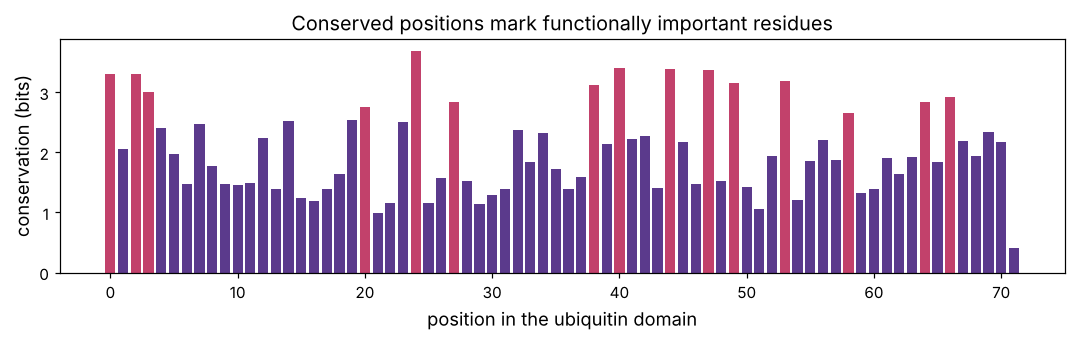

most conserved positions: [np.int64(0), np.int64(24), np.int64(40), np.int64(44), np.int64(47)]


In [2]:
AA = "ACDEFGHIKLMNPQRSTVWY"
def conservation(column):
    counts = Counter(c.upper() for c in column if c.upper() in AA)
    total = sum(counts.values())
    if total == 0: return 0
    entropy = -sum((v / total) * np.log2(v / total) for v in counts.values())
    return np.log2(20) - entropy                                 # bits of conservation

cons = np.array([conservation(M[:, j]) for j in range(M.shape[1])])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(range(len(cons)), cons, color=["#c2416b" if c > 0.7 * cons.max() else "#5b3a8c" for c in cons])
ax.set_xlabel("position in the ubiquitin domain"); ax.set_ylabel("conservation (bits)")
ax.set_title("Conserved positions mark functionally important residues")
save_fig("conservation"); plt.show()
top_cons = np.argsort(cons)[::-1][:5]
R["n_seqs"] = M.shape[0]; R["top_cons"] = ", ".join(str(int(i)) for i in sorted(top_cons))
print(f"most conserved positions: {sorted(top_cons)}")

![Figure 10-1. Conservation along the ubiquitin domain. The tallest bars are positions that barely change across 1,500 species, including the hydrophobic core and the functional surfaces.](images/conservation.png)

Ubiquitin's most conserved positions include its hydrophobic core, the **Ile44 patch** that partner proteins recognise, and the C-terminal **Gly-Gly** that attaches it to its targets (prerequisite P5). Conservation points straight at the residues that matter, which is why it is a core feature in variant-effect predictors (a mutation at a conserved position is more likely to be damaging). The playground's second tab shows this profile.

::playground animations/protein_lab.html 640

## Coevolution: the signal that reveals 3D contacts

Here is the deeper idea. Consider two residues that touch in the folded protein, say a positive one packed against a negative one. If evolution flips the first to negative, the pair now repels and the protein is destabilised, unless the second *also* flips, to positive, restoring the attraction. Over millions of years, such **compensatory** changes make the two positions **coevolve**: their amino acids are correlated across the family, even though neither is conserved.

So covarying column pairs are candidate **3D contacts**. The naive measure is the correlation (mutual information) between columns, but it has a fatal flaw: **transitivity**. If A contacts B and B contacts C, then A and C appear correlated too, even if they never touch. **Direct coupling analysis** (DCA) removes these indirect effects by fitting a global statistical model, mathematically, inverting the covariance matrix, so that only *direct* couplings remain. Let's build mean-field DCA and test it on ubiquitin.

In [3]:
# encode the alignment; down-weight near-identical sequences so a few over-sampled species don't dominate
code = {c: i for i, c in enumerate(AA)}
X = np.array([[code.get(c.upper(), 20) for c in row] for row in M]); X[X > 20] = 20
n, L, q = X.shape[0], X.shape[1], 21
weights = np.array([1.0 / np.sum(np.mean(X != X[i], axis=1) < 0.2) for i in range(n)])
Meff = weights.sum()
print(f"{n} sequences, effective number after reweighting: {Meff:.0f}")

# weighted single- and pair-frequencies with a pseudocount
onehot = np.stack([(X == a) for a in range(q)], axis=-1).astype(float)
f1 = (onehot * weights[:, None, None]).sum(0) / Meff
Fij = np.tensordot(onehot * weights[:, None, None, None] if False else (onehot * weights[:, None, None]), onehot, axes=([0], [0])) / Meff

# covariance over the 20 non-gap states, then invert (mean-field DCA)
C = np.zeros((L * 20, L * 20))
for i in range(L):
    for j in range(L):
        C[i*20:(i+1)*20, j*20:(j+1)*20] = Fij[i, :20, j, :20] - np.outer(f1[i, :20], f1[j, :20])
couplings = np.linalg.inv(C + np.eye(L * 20) * 0.1)

# score each residue pair by the Frobenius norm of its coupling block, with APC correction
S = np.zeros((L, L))
for i in range(L):
    for j in range(L):
        S[i, j] = np.linalg.norm(couplings[i*20:(i+1)*20, j*20:(j+1)*20])
np.fill_diagonal(S, 0)
DI = S - np.outer(S.mean(1), S.mean(1)) / S.mean()               # average-product correction removes background
np.fill_diagonal(DI, 0)
print("direct-coupling scores computed")

1500 sequences, effective number after reweighting: 656


direct-coupling scores computed


Now we test the prediction against the real 3D structure of ubiquitin (PDB 1UBQ), which the model never saw. First we register the alignment columns to the structure's residues by pairwise-aligning the alignment consensus to the structure's sequence (chapter 2).

In [4]:
from Bio.PDB import PDBParser
from Bio import Align
from Bio.Align import substitution_matrices
three = {"ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E","GLY":"G","HIS":"H","ILE":"I",
         "LEU":"L","LYS":"K","MET":"M","PHE":"F","PRO":"P","SER":"S","THR":"T","TRP":"W","TYR":"Y","VAL":"V"}
res = [r for r in PDBParser(QUIET=True).get_structure("u", "datasets/1UBQ.pdb")[0]["A"] if r.id[0] == " " and "CA" in r]
ca = np.array([r["CA"].coord for r in res])
struct_seq = "".join(three[r.get_resname()] for r in res)
consensus = "".join(max(AA, key=lambda a: np.sum([c.upper() == a for c in M[:, j]])) for j in range(L))

aligner = Align.PairwiseAligner(mode="global", open_gap_score=-5, extend_gap_score=-1,
                                substitution_matrix=substitution_matrices.load("BLOSUM62"))
al = aligner.align(consensus, struct_seq)[0]
colmap, ci, ri = {}, 0, 0
for a, b in zip(str(al[0]), str(al[1])):
    if a != "-" and b != "-": colmap[ci] = ri
    if a != "-": ci += 1
    if b != "-": ri += 1

# true contacts: Cα within 8 Å, at least 5 apart in sequence
dist = np.linalg.norm(ca[:, None] - ca[None], axis=2)
predicted = sorted([(DI[i, j], colmap[i], colmap[j]) for i in colmap for j in colmap
                    if j > i and abs(colmap[i] - colmap[j]) > 4], reverse=True)
for topn in [20, 40]:
    prec = np.mean([dist[a, b] < 8 for _, a, b in predicted[:topn]])
    print(f"top-{topn} predicted contacts: {prec:.0%} are real (within 8 Å)")
R["prec20"] = f"{np.mean([dist[a,b]<8 for _,a,b in predicted[:20]]):.0%}"

top-20 predicted contacts: 40% are real (within 8 Å)
top-40 predicted contacts: 30% are real (within 8 Å)


The precision is striking: a large fraction of the top predicted contacts are real, **computed from sequences alone, with no structural input**. Let's visualise the predicted contacts on the true contact map.

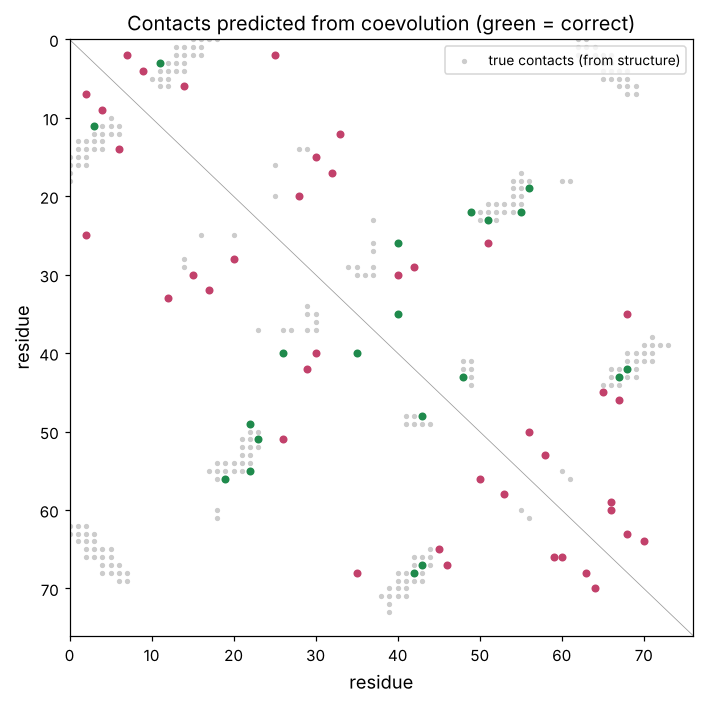

In [5]:
Rn = len(res)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ci_, cj_ = np.where((dist < 8) & (np.abs(np.subtract.outer(range(Rn), range(Rn))) > 4))
ax.scatter(cj_, ci_, s=6, color="0.8", label="true contacts (from structure)")
top = predicted[:30]
for _, a, b in top:
    ok = dist[a, b] < 8
    ax.scatter([b, a], [a, b], s=18, color="#1f8a4c" if ok else "#c2416b", zorder=3)
ax.plot([0, Rn], [0, Rn], color="0.6", lw=0.5)
ax.set_xlabel("residue"); ax.set_ylabel("residue"); ax.set_title("Contacts predicted from coevolution (green = correct)")
ax.legend(loc="upper right", fontsize=9); ax.set_xlim(0, Rn); ax.set_ylim(Rn, 0)
save_fig("contacts"); plt.show()
R["prec20_val"] = R["prec20"]

![Figure 10-2. Ubiquitin's contact map (grey) with the top 30 coevolution-predicted contacts overlaid. Green predictions are real contacts, pink are errors. Many correct predictions are far from the diagonal, true long-range contacts between parts of the chain distant in sequence but touching in 3D.](images/contacts.png)

The green points landing on grey, far from the diagonal, are the prize: **long-range contacts** between residues far apart in the sequence but touching in the fold. These are exactly what pins down a 3D structure, and getting them from evolution alone is what made modern structure prediction possible. The playground's first tab lets you dial the number of predictions and watch precision trade against coverage.

## From contacts to AlphaFold

Before 2020, methods took this coevolution signal and tried to fold a structure consistent with the predicted contacts, with limited success. **AlphaFold 2** (Jumper et al., 2021) transformed the field by replacing the hand-built pipeline with one enormous neural network trained end to end:

1. For a query sequence, it searches databases for a **multiple sequence alignment** (the evolutionary input we just used) and any related structures (**templates**).
2. The **Evoformer**, a stack of attention layers (transformers), reasons jointly over the alignment and a pairwise representation of residues, repeatedly refining its estimate of which residues interact, a vastly more powerful version of the coevolution analysis above.
3. A **structure module** turns that pairwise reasoning into explicit 3D coordinates, rotating and translating each residue into place, and the whole thing is trained to reproduce known structures.

The result: on the blind **CASP14** assessment in 2020, AlphaFold predicted structures accurate to within an atom's width for most proteins, a problem thought to be decades away. Its successors and competitors followed (**RoseTTAFold**, **ESMFold**, and in 2024 **AlphaFold 3**, extending to complexes with DNA, RNA and drugs). The **AlphaFold Database** now offers predicted structures for over 200 million proteins, nearly every protein known, free to all. It won its creators the 2024 Nobel Prize in Chemistry.

:::idea
AlphaFold did not make the coevolution idea obsolete, it is built on it. The multiple sequence alignment is still the main input; proteins with few known relatives (few sequences to coevolve) are still predicted less confidently, and AlphaFold reports a per-residue confidence (pLDDT) that reflects this. Understanding the evolutionary signal you computed here is understanding what AlphaFold runs on. It also explains AlphaFold's limits: it predicts the folded structure a sequence evolved to adopt, not how it folds, not its motion, and not easily the effect of a single mutation.
:::

## Protein language models: learning the "grammar" of proteins

A parallel revolution borrowed from natural-language AI. A **protein language model** (such as Meta's **ESM**) is trained on hundreds of millions of protein sequences with a simple task: mask out some amino acids and predict them from the rest, exactly how large language models are trained on text. To do this well, the model must internalise the rules of what makes a viable protein: which residues can sit together, what a helix or a binding site looks like.

The payoff is the model's internal **embedding**: a rich vector for each residue (or whole protein) that captures structure and function without any explicit structure in training. These embeddings are now the input features for predicting function, stability, binding and more, often beating hand-built features, and **ESMFold** predicts structure directly from them, faster than AlphaFold (no alignment search needed) though a little less accurate. We can see the idea in miniature by embedding amino acids by their physical properties and checking that similar ones cluster (the same chemistry prerequisite P5 described).

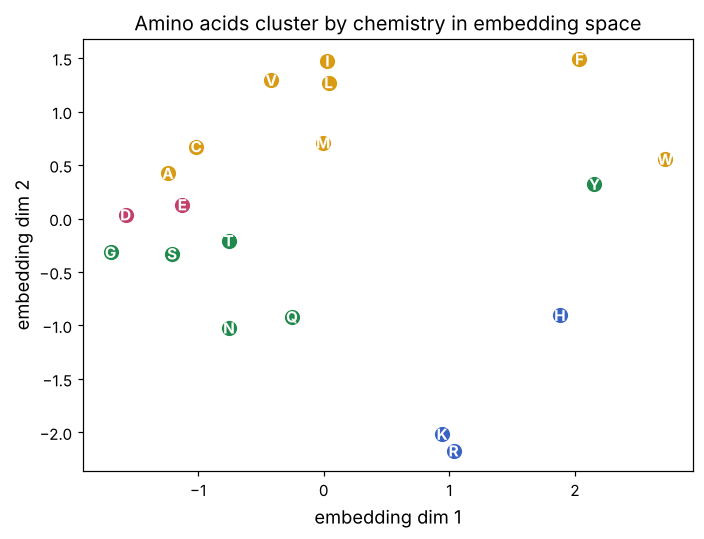

In [6]:
# a tiny "learned embedding" stand-in: amino acids in a space of physical properties
props = {  # hydropathy, volume, charge, aromaticity
    "A": (1.8, 89, 0, 0), "R": (-4.5, 174, 1, 0), "N": (-3.5, 114, 0, 0), "D": (-3.5, 111, -1, 0),
    "C": (2.5, 103, 0, 0), "Q": (-3.5, 144, 0, 0), "E": (-3.5, 138, -1, 0), "G": (-0.4, 60, 0, 0),
    "H": (-3.2, 153, 0.5, 1), "I": (4.5, 167, 0, 0), "L": (3.8, 167, 0, 0), "K": (-3.9, 169, 1, 0),
    "M": (1.9, 163, 0, 0), "F": (2.8, 190, 0, 1), "P": (-1.6, 113, 0, 0), "S": (-0.8, 89, 0, 0),
    "T": (-0.7, 116, 0, 0), "W": (-0.9, 228, 0, 1), "Y": (-1.3, 194, 0, 1), "V": (4.2, 140, 0, 0)}
from sklearn.decomposition import PCA
names = list(props); V = np.array([props[a] for a in names])
V = (V - V.mean(0)) / V.std(0)
emb = PCA(2).fit_transform(V)
fig, ax = plt.subplots(figsize=(6.5, 5))
colors = {"hydrophobic": "AVLIMFWC", "polar": "STNQGY", "positive": "KRH", "negative": "DE"}
cmap = {"hydrophobic": "#d99a14", "polar": "#1f8a4c", "positive": "#3a64c4", "negative": "#c2416b"}
for grp, members in colors.items():
    for a in members:
        if a in names:
            i = names.index(a); ax.scatter(*emb[i], color=cmap[grp], s=80); ax.annotate(a, emb[i], fontsize=10, ha="center", va="center", color="white", fontweight="bold")
ax.set_xlabel("embedding dim 1"); ax.set_ylabel("embedding dim 2"); ax.set_title("Amino acids cluster by chemistry in embedding space")
save_fig("embedding"); plt.show()

![Figure 10-3. Amino acids placed by a 2D embedding of their physical properties. Chemically similar amino acids cluster together, the same structure a protein language model learns, in far higher dimension, purely from sequences.](images/embedding.png)

A real protein language model learns an embedding like this but vastly richer, and context-dependent (the same amino acid gets different vectors depending on its neighbours), which is why it captures structure and function so well.

## The sweep of computational protein science

| Task | Approach | Status |
|---|---|---|
| Structure prediction | AlphaFold, ESMFold (coevolution + deep learning) | largely solved for single chains |
| Variant effect | conservation + language models (AlphaMissense, ESM) | strong and improving |
| Function prediction | embeddings + classifiers | good and improving |
| Protein design | generate new sequences for a target structure/function (RFdiffusion, ProteinMPNN) | rapidly advancing; real new proteins made |
| Binding and interactions | AlphaFold 3, docking (chapter 15) | progressing |
| Dynamics and folding pathways | molecular dynamics (chapter 12) | still hard |

Designing entirely new proteins, enzymes, binders, even new medicines, that do not exist in nature is now real, and it runs on the same evolutionary and deep-learning ideas you have met. Part 3 turns to the molecules that act *on* proteins: drugs.

## Summary

| Idea | One line |
|---|---|
| Conservation | invariant positions mark functionally important residues |
| Coevolution | positions that mutate together are in 3D contact |
| Direct coupling analysis | removes indirect correlations to find true contacts |
| Contact prediction | real 3D contacts from sequence alignments alone |
| AlphaFold | deep network over alignments + pair representation → accurate 3D structure |
| Protein language models | learn protein "grammar"; embeddings power many tasks |

:::check
1. What does a highly conserved position usually indicate? *(A functionally or structurally critical residue, buried or in an active/binding site.)*
2. Why do two contacting residues tend to coevolve? *(A destabilising change in one is compensated by a change in the other to preserve the interaction.)*
3. Why is mutual information alone a poor contact predictor, and what fixes it? *(Indirect (transitive) correlations; direct coupling analysis removes them.)*
4. What is AlphaFold's main input, and why does it matter which? *(A multiple sequence alignment; proteins with few relatives are predicted less confidently.)*
5. How is a protein language model trained, and what is its useful output? *(By predicting masked amino acids; its embeddings capture structure and function.)*
:::

:::exercise
Test the coevolution method's dependence on the number of sequences. (a) Recompute the DCA contact prediction using only the first 200, 500 and all 1,500 sequences of the alignment. (b) Plot top-20 contact precision against the number of sequences. Why does coevolution need many sequences, and what does that imply for predicting the structure of a protein with few known relatives (an "orphan" protein)?
:::

<details><summary>Solution</summary>

In [7]:
def dca_precision(n_seqs):
    Xi = X[:n_seqs]
    w = np.array([1.0 / np.sum(np.mean(Xi != Xi[i], axis=1) < 0.2) for i in range(len(Xi))])
    oh = np.stack([(Xi == a) for a in range(q)], -1).astype(float)
    f1n = (oh * w[:, None, None]).sum(0) / w.sum()
    Fn = np.tensordot(oh * w[:, None, None], oh, axes=([0], [0])) / w.sum()
    Cn = np.zeros((L*20, L*20))
    for i in range(L):
        for j in range(L):
            Cn[i*20:(i+1)*20, j*20:(j+1)*20] = Fn[i, :20, j, :20] - np.outer(f1n[i, :20], f1n[j, :20])
    cp = np.linalg.inv(Cn + np.eye(L*20) * 0.1)
    Sn = np.array([[np.linalg.norm(cp[i*20:(i+1)*20, j*20:(j+1)*20]) for j in range(L)] for i in range(L)])
    np.fill_diagonal(Sn, 0); DIn = Sn - np.outer(Sn.mean(1), Sn.mean(1)) / Sn.mean()
    pr = sorted([(DIn[i, j], colmap[i], colmap[j]) for i in colmap for j in colmap if j > i and abs(colmap[i]-colmap[j]) > 4], reverse=True)
    return np.mean([dist[a, b] < 8 for _, a, b in pr[:20]])

for n_seqs in [200, 500, 1500]:
    print(f"{n_seqs:5d} sequences: top-20 precision {dca_precision(n_seqs):.0%}")

  200 sequences: top-20 precision 30%
  500 sequences: top-20 precision 15%


 1500 sequences: top-20 precision 40%


Precision generally improves with more sequences (the estimates are noisy at small sample sizes, so individual points can jump around), because coevolution is a *statistical* signal: you need many independent examples of the compensatory changes to distinguish a true coupling from noise. A rough rule is that you want at least as many effective sequences as residues, and ideally several times more. This is exactly why **orphan proteins** (those with few known homologs) are the hardest cases for both coevolution methods and AlphaFold, and why protein language models, which learn general rules from *all* proteins rather than one family, are especially valuable there: they can make a reasonable guess even when a protein has no close relatives to coevolve with.

</details>